# SPX：三種 TimeDiff 模型一起比較

比較 **Mixup**、**No mixup**、**No mixup + loss（λ=0.1）**，沿用已完成的七組情境與每組 200 條路徑。
本 notebook 只分析保存結果，**不重訓、不重新取樣、不加入 CFG**。

三組生成器皆看 63 天歷史、生成 21 天；AR 預訓 500 步後固定，diffusion 訓練 2,000 步。
Mixup 在訓練時將真實未來混入歷史條件分支；No mixup 移除此機制。
第三組再加入 `L = L_diffusion + 0.1 L_return + 0.1 L_volatility`，
以單步去噪的乾淨路徑估計，逐路徑計算標準化條件誤差；不是生成後強行調整路徑。

以下沿用前幾份 notebook 的比較內容：設定核對、原始路徑重算、邊際分布、聯合符合度、
訓練／驗證曲線、範例路徑、誤差差值、歷史支持、loss 分項與已有的計時。
各組依相同驗證規則選 checkpoint，最佳步數可以不同。

這是單一歷史起點、seed 與 SPX 標的的生成品質診斷，尚無 FinRL 績效；
63 天是生成器輸入長度，未來 RL 的價格觀察窗口仍是 50 天。

## 1. 執行與資料來源

從頭執行所有 cells 即可。也可在 TimeDiff 目錄執行：

```bash
python3 notebooks/execute_in_process.py notebooks/spx_three_way_comparison.ipynb
```

下格集中設定三組 train/sample 來源與獨立匯出目錄，避免覆蓋先前的比較結果。
所有來源必須完整存在；若改用其他實驗，需通過後續設定一致性檢查。

報酬為 **21 日累積簡單報酬**，波動率為 **日 log return 樣本標準差 × √252**。
命中要求同一路徑的報酬誤差 ≤2 百分點、年化波動率誤差 ≤5 百分點。
這兩個條件不構成完整市場分布定義，不假設常態分布。

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Rectangle
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'spx_experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('請從 TimeDiff 或其子目錄啟動 notebook')
CRASH_RUN = ROOT / 'outputs/spx/crash_20260929'
LOSS_RUN = ROOT / 'outputs/spx/condition_lambda_0p1'
RUNS = {
    'Mixup': {'train': ROOT/'outputs/spx/initial', 'samples': CRASH_RUN/'mixup_samples'},
    'No mixup': {'train': CRASH_RUN/'train', 'samples': CRASH_RUN/'no_mixup_samples'},
    'No mixup + loss': {'train': LOSS_RUN/'train', 'samples': LOSS_RUN/'samples'},
}
COLORS = {'Mixup': '#89929B', 'No mixup': '#3976B8', 'No mixup + loss': '#D68A27'}
STYLES = {'Mixup': ':', 'No mixup': '--', 'No mixup + loss': '-'}
MARKERS = {'Mixup': 'o', 'No mixup': '^', 'No mixup + loss': 's'}
EXPORT = ROOT / 'outputs/spx/three_way_comparison'
EXPORT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': 0.18})

loaded = {}
for label, locations in RUNS.items():
    required = [locations['train']/name for name in ['metadata.json', 'training.csv']]
    required += [locations['samples']/name for name in
                 ['sampling.json', 'paths.csv', 'path_metrics.csv', 'summary.csv', 'history_features.csv']]
    missing = [str(p) for p in required if not p.is_file()]
    if missing:
        raise FileNotFoundError('先完成該組 train/sample：' + ', '.join(missing))
    loaded[label] = {
        'meta': json.loads((locations['train']/'metadata.json').read_text()),
        'sampling': json.loads((locations['samples']/'sampling.json').read_text()),
        'training': pd.read_csv(locations['train']/'training.csv'),
        'paths': pd.read_csv(locations['samples']/'paths.csv'),
        'saved_metrics': pd.read_csv(locations['samples']/'path_metrics.csv'),
        'saved_summary': pd.read_csv(locations['samples']/'summary.csv'),
        'history': pd.read_csv(locations['samples']/'history_features.csv'),
    }


## 2. 確認比較設定與資料一致

核對資料指紋、切分、scaler、模型共通參數、取樣 seed、歷史、目標條件與路徑數。
只允許 mixup 與條件 loss 等預期差異；各組完整取樣參數以 metadata 為準。
舊版 Mixup 沒有完整 CLI 與 commit，因此訓練步數由 training.csv 核對；未保存的欄位不宣稱已驗證。
同 seed 不代表開關 mixup 後，訓練亂數消耗仍完全一致。

In [2]:
base = loaded['No mixup']
new = loaded['No mixup + loss']
expected = {'Mixup': (True, 0.), 'No mixup': (False, 0.), 'No mixup + loss': (False, .1)}
allowed_differences = {'use_future_mixup', 'device', 'lambda_condition',
                       'condition_feature_scaler', 'condition_label_scaler'}
for label, data in loaded.items():
    for key in ['data_sha256', 'train_end', 'val_end', 'seed', 'ar_steps',
                'feature_scaler', 'condition_scaler', 'split_windows']:
        assert base['meta'][key] == data['meta'][key], f'{label}: 訓練設定不一致：{key}'
    left = {k:v for k,v in base['meta']['args'].items() if k not in allowed_differences}
    right = {k:v for k,v in data['meta']['args'].items() if k not in allowed_differences}
    assert left == right, f'{label}: 模型共通設定不一致'
    mixup, weight = expected[label]
    assert data['meta']['args'].get('use_future_mixup', True) == mixup
    assert data['meta']['args'].get('lambda_condition', 0.) == weight
    assert data['meta']['ar_frozen'] is True
    assert data['sampling']['future_mixup_in_training'] == mixup
    assert data['sampling'].get('lambda_condition', 0.) == weight
    assert data['sampling']['market_condition_enabled'] is True
    for key in ['data_sha256', 'history_end', 'seed', 'n_paths', 'conditions',
                'return_tolerance', 'volatility_tolerance', 'batch_size']:
        assert base['sampling'][key] == data['sampling'][key], f'{label}: 取樣設定不一致：{key}'
    assert data['sampling']['data_sha256'] == data['meta']['data_sha256']
    pd.testing.assert_frame_equal(base['history'], data['history'])
    np.testing.assert_array_equal(base['training']['step'], data['training']['step'])
    assert data['training']['step'].max() == 2000
for key in ['lr','batch_size','ar_steps','steps','eval_every','val_batches','channels',
            'parameterization','sampler','no_market_condition','threads']:
    assert base['meta']['training_config'][key] == new['meta']['training_config'][key]
price_path = ROOT/'datasets/spx/prices.csv'
if price_path.exists():
    assert hashlib.sha256(price_path.read_bytes()).hexdigest() == base['meta']['data_sha256']
targets = np.asarray(base['sampling']['conditions'])
assert targets.shape == (7, 2)
TOL_R = base['sampling']['return_tolerance']
TOL_V = base['sampling']['volatility_tolerance']
provenance = pd.DataFrame([{
    'method': label, 'mixup': expected[label][0], 'lambda': expected[label][1],
    'best_step': d['meta']['best_step'],
    'validation_condition_mse': d['meta']['best_validation_condition_mse'],
    'train_seed': d['meta']['seed'], 'sampling_seed': d['sampling']['seed'],
    'history_end': d['sampling']['history_end'], 'paths_per_condition': d['sampling']['n_paths'],
    'code_commit': d['meta'].get('code_commit', '未記錄（舊版）'),
} for label,d in loaded.items()])
display(provenance)
provenance.to_csv(EXPORT/'provenance.csv', index=False)


,method,mixup,lambda,best_step,validation_condition_mse,train_seed,sampling_seed,history_end,paths_per_condition,code_commit
0,Mixup,True,0.0,100,1.049102,2024,2024,2023-12-29,200,未記錄（舊版）
1,No mixup,False,0.0,900,0.485747,2024,2024,2023-12-29,200,30bbb731131cc1cbaa9c7cc87130f767e24c0ffa
2,No mixup + loss,False,0.1,2000,0.332294,2024,2024,2023-12-29,200,e6f2c4b53596d4933bec5a53c888ffa633eb0658


## 3. 由原始路徑重算指標

使用 21 個每日 log return，包含歷史最後收盤到第一個生成日的報酬：

- 累積報酬：`expm1(sum(rclose))`。
- 年化波動率：`std(rclose, ddof=1) * sqrt(252)`。
- MAE：每條路徑與指定條件的絕對差，再跨路徑平均。

先重算每條路徑，再核對已儲存的 metrics 與 summary。沒有先平均價格路徑才計算波動率。
5%–95% 是生成樣本的分位數區間，不是平均值的信賴區間。

In [3]:
metric_frames, rows = [], []
for label, data in loaded.items():
    paths = data['paths'].sort_values(['scenario', 'path', 'step'])
    assert len(paths) == len(targets)*data['sampling']['n_paths']*21
    np.testing.assert_array_equal(paths.scenario.unique(), np.arange(len(targets)))
    assert not paths.duplicated(['scenario', 'path', 'step']).any()
    assert np.isfinite(paths.select_dtypes('number')).all().all()
    assert (paths.low <= paths.close).all() and (paths.close <= paths.high).all()
    groups = paths.groupby(['scenario', 'path'], sort=True)
    assert groups.size().eq(21).all()
    assert groups['step'].apply(lambda x: np.array_equal(x, np.arange(1, 22))).all()
    stats = groups['rclose'].agg(
        actual_return=lambda r: np.expm1(r.sum()),
        actual_volatility=lambda r: r.std(ddof=1)*np.sqrt(252),
    ).reset_index()
    saved = data['saved_metrics'].sort_values(['scenario', 'path']).reset_index(drop=True)
    np.testing.assert_array_equal(stats[['scenario', 'path']], saved[['scenario', 'path']])
    np.testing.assert_allclose(stats[['actual_return', 'actual_volatility']],
                               saved[['return', 'volatility']], rtol=1e-5, atol=1e-7)
    stats['method'] = label
    stats['target_return'] = targets[stats.scenario.to_numpy(), 0]
    stats['target_volatility'] = targets[stats.scenario.to_numpy(), 1]
    stats['return_error'] = stats.actual_return - stats.target_return
    stats['volatility_error'] = stats.actual_volatility - stats.target_volatility
    stats['hit'] = (stats.return_error.abs() <= TOL_R) & (stats.volatility_error.abs() <= TOL_V)
    np.testing.assert_array_equal(stats['hit'], saved['hit'])
    metric_frames.append(stats)
    for scenario, g in stats.groupby('scenario'):
        p = paths[paths.scenario == scenario]
        assert len(g) == data['sampling']['n_paths']
        np.testing.assert_allclose(p[['target_return', 'target_volatility']],
                                   np.tile(targets[scenario], (len(p), 1)))
        row = dict(method=label, scenario=scenario, n=len(g),
                   target_return=targets[scenario, 0], target_volatility=targets[scenario, 1],
                   return_mean=g.actual_return.mean(), volatility_mean=g.actual_volatility.mean(),
                   return_mae=g.return_error.abs().mean(), volatility_mae=g.volatility_error.abs().mean(),
                   return_p05=g.actual_return.quantile(.05), return_p95=g.actual_return.quantile(.95),
                   volatility_p05=g.actual_volatility.quantile(.05), volatility_p95=g.actual_volatility.quantile(.95),
                   joint_hit_rate=g.hit.mean(), rhigh_clip_rate=(p.rhigh_raw < 0).mean(),
                   rlow_clip_rate=(p.rlow_raw > 0).mean())
        saved_row = data['saved_summary'].set_index('scenario').loc[scenario]
        for key in row.keys() - {'method', 'scenario', 'n'}:
            np.testing.assert_allclose(row[key], saved_row[key], rtol=1e-5, atol=1e-7)
        rows.append(row)
metrics = pd.concat(metric_frames, ignore_index=True)
summary = pd.DataFrame(rows).sort_values(['scenario', 'method'])
summary.to_csv(EXPORT/'comparison_summary.csv', index=False)
cols = ['method', 'scenario', 'n', 'target_return', 'target_volatility', 'return_mean',
        'volatility_mean', 'return_mae', 'volatility_mae', 'joint_hit_rate', 'rhigh_clip_rate', 'rlow_clip_rate']
formats = {k: '{:.2%}' for k in cols if k not in {'method', 'scenario', 'n'}}
formats.update({k: lambda v: f'{100*v:.2f} pp' for k in ['return_mae','volatility_mae']})
display(summary[cols].style.format(formats))
print(f'核對通過：{len(metrics):,} 條路徑；MAE 的 pp 表示百分點。')


核對通過：4,200 條路徑；MAE 的 pp 表示百分點。


,method,scenario,n,target_return,target_volatility,return_mean,volatility_mean,return_mae,volatility_mae,joint_hit_rate,rhigh_clip_rate,rlow_clip_rate
0,Mixup,0,200,-5.00%,15.00%,-1.17%,14.81%,4.92 pp,2.09 pp,25.50%,22.24%,24.93%
7,No mixup,0,200,-5.00%,15.00%,-4.34%,14.89%,2.78 pp,1.74 pp,42.50%,8.88%,15.52%
14,No mixup + loss,0,200,-5.00%,15.00%,-4.35%,16.03%,2.13 pp,1.89 pp,53.50%,9.14%,12.74%
1,Mixup,1,200,5.00%,15.00%,6.03%,14.31%,4.31 pp,2.05 pp,25.50%,31.43%,20.05%
8,No mixup,1,200,5.00%,15.00%,2.64%,14.23%,3.64 pp,1.79 pp,28.50%,15.21%,10.71%
15,No mixup + loss,1,200,5.00%,15.00%,4.36%,15.42%,2.32 pp,1.77 pp,49.50%,18.19%,9.69%
2,Mixup,2,200,-5.00%,35.00%,4.32%,16.58%,9.47 pp,18.42 pp,0.00%,26.00%,12.86%
9,No mixup,2,200,-5.00%,35.00%,-4.74%,28.76%,3.98 pp,6.37 pp,14.50%,7.86%,12.57%
16,No mixup + loss,2,200,-5.00%,35.00%,-4.89%,34.32%,3.27 pp,2.87 pp,32.00%,14.88%,13.26%
3,Mixup,3,200,5.00%,35.00%,11.19%,16.06%,6.94 pp,18.94 pp,0.00%,26.81%,7.57%


## 4. 各條件的統計量分布

每列一個指定條件，三組使用同一組 bins；每欄共用尺度，避免視覺上誇大差異。
黑色虛線是目標，灰色區域是容許誤差。柱形顯示實際路徑數，不假設分布形狀。

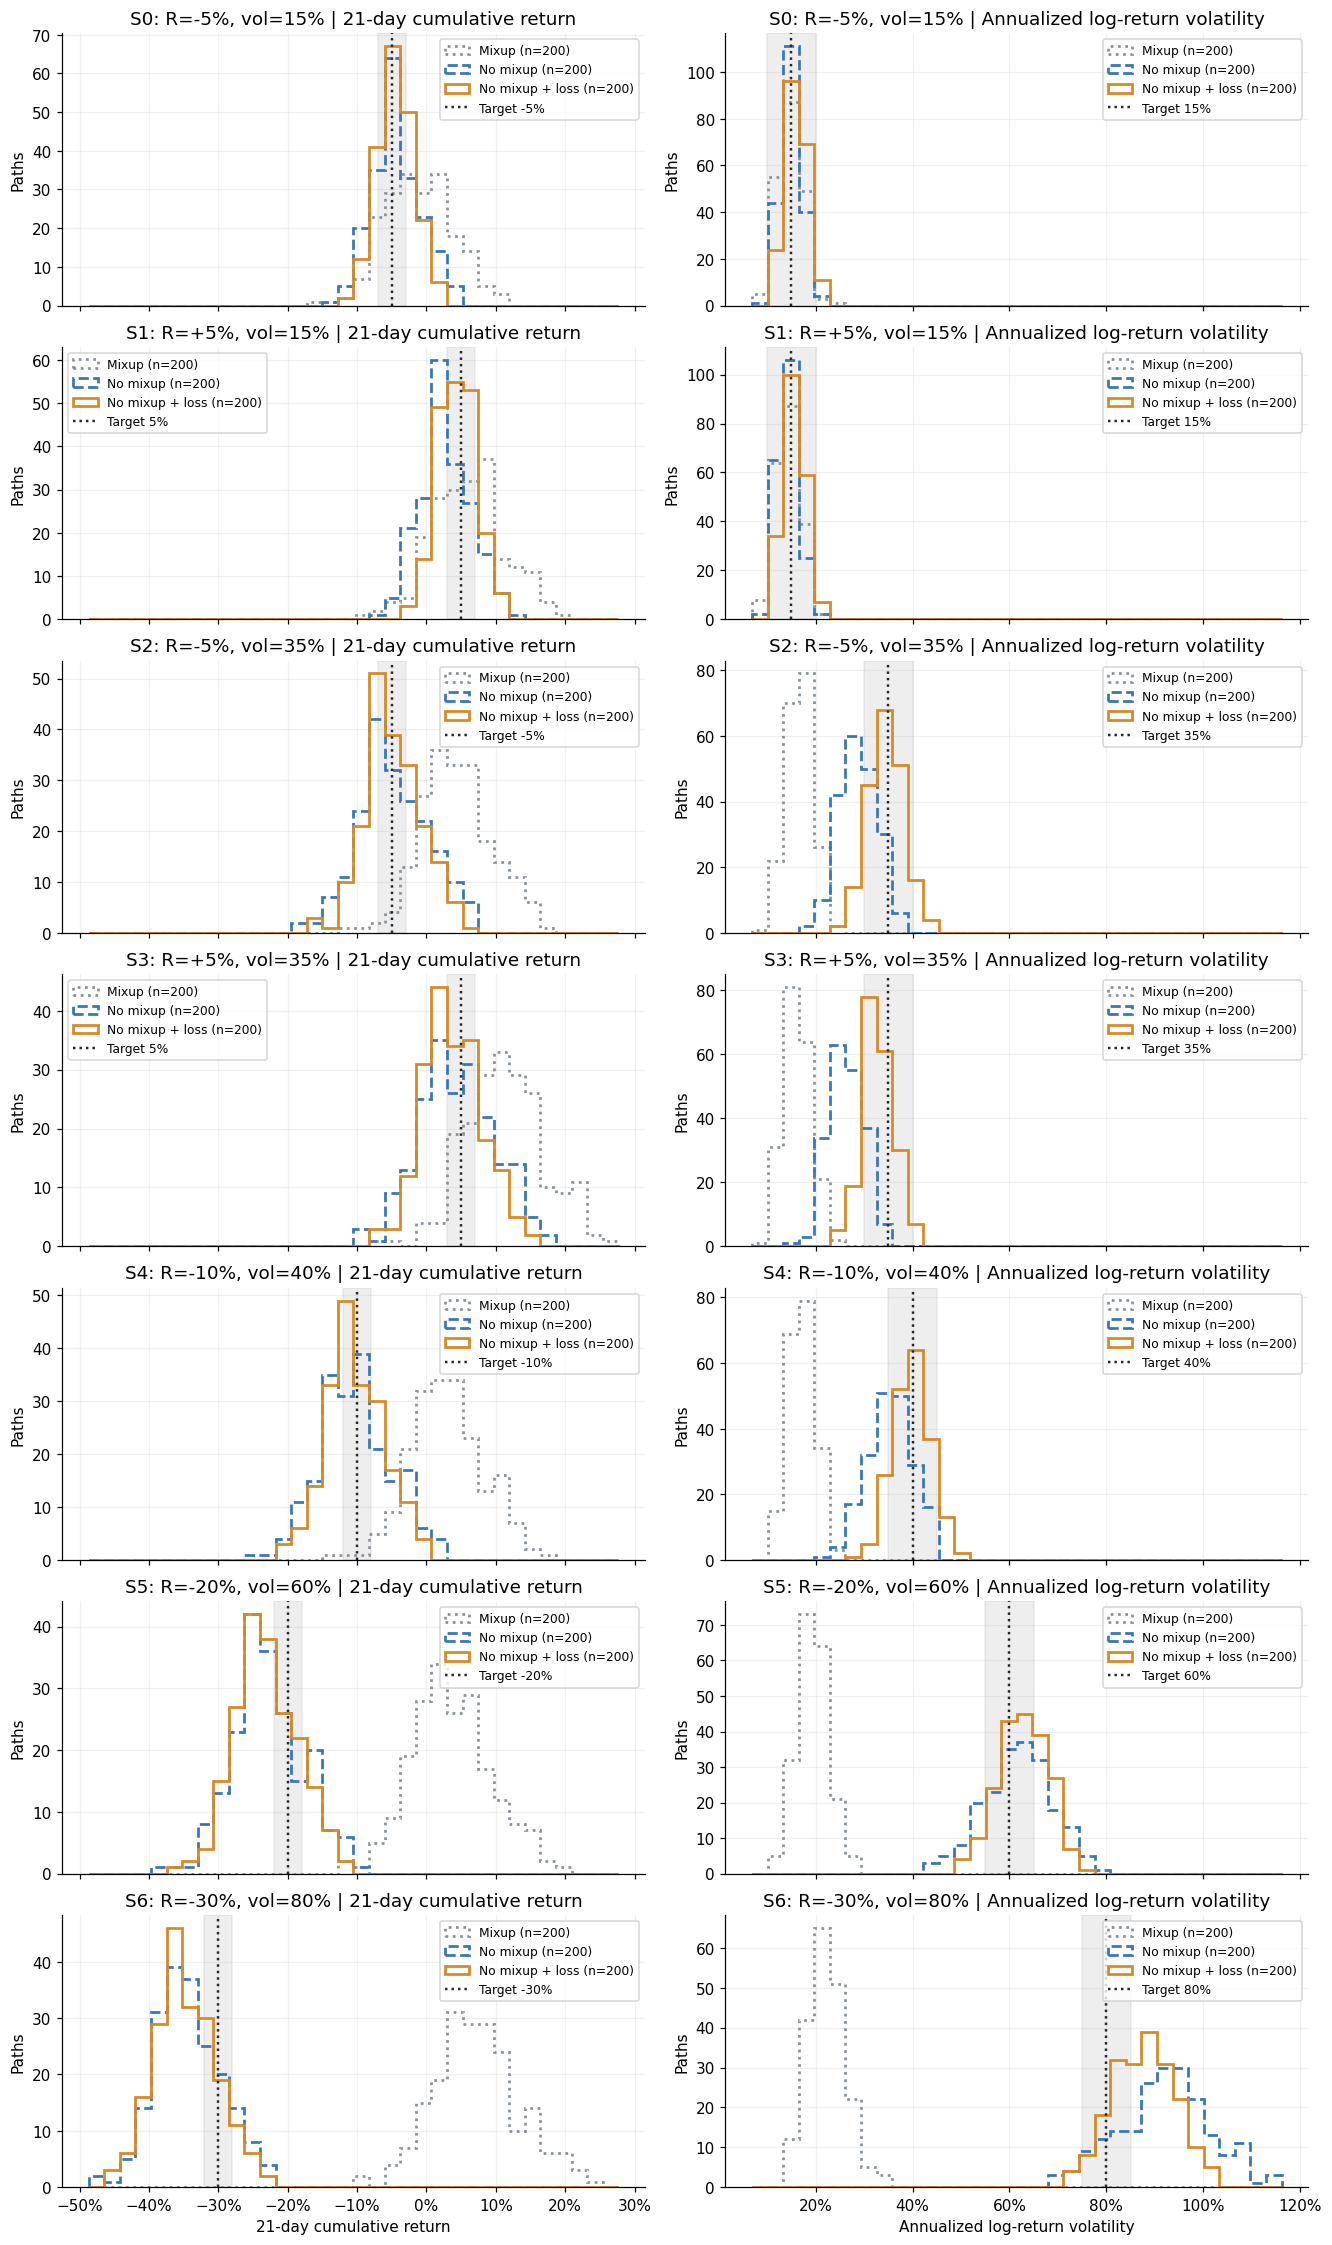

In [4]:
fig, axes = plt.subplots(len(targets), 2, figsize=(12, 2.9*len(targets)), sharex='col', constrained_layout=True)
for j, (metric, tolerance, title) in enumerate([
    ('actual_return', TOL_R, '21-day cumulative return'),
    ('actual_volatility', TOL_V, 'Annualized log-return volatility'),
]):
    lower = min(metrics[metric].min(), (targets[:, j]-tolerance).min())
    upper = max(metrics[metric].max(), (targets[:, j]+tolerance).max())
    bins = np.linspace(lower-.01, upper+.01, 35)
    for scenario in range(len(targets)):
        ax = axes[scenario, j]
        target = targets[scenario, j]
        ax.axvspan(target-tolerance, target+tolerance, color='#777777', alpha=.12)
        for label in RUNS:
            values = metrics.loc[(metrics.method == label) & (metrics.scenario == scenario), metric]
            ax.hist(values, bins=bins, histtype='step', linewidth=1.8,
                    color=COLORS[label], linestyle=STYLES[label], label=f'{label} (n={len(values)})')
        ax.axvline(target, color='#252525', linestyle=':', linewidth=1.6, label=f'Target {target:.0%}')
        ax.set_title(f'S{scenario}: R={targets[scenario, 0]:+.0%}, vol={targets[scenario, 1]:.0%} | {title}')
        ax.set_ylabel('Paths')
        ax.xaxis.set_major_formatter(PercentFormatter(1))
        ax.legend(fontsize=8)
        if scenario == len(targets)-1:
            ax.set_xlabel(title)
fig.savefig(EXPORT/'condition_histograms.png', dpi=150)
plt.show()


## 5. 聯合符合度

報酬與波動率必須在同一條路徑同時符合目標。十字是指定條件，灰色矩形是聯合命中範圍。
各子圖共用座標尺度；單獨看兩個邊際平均值可能掩蓋未命中的路徑。

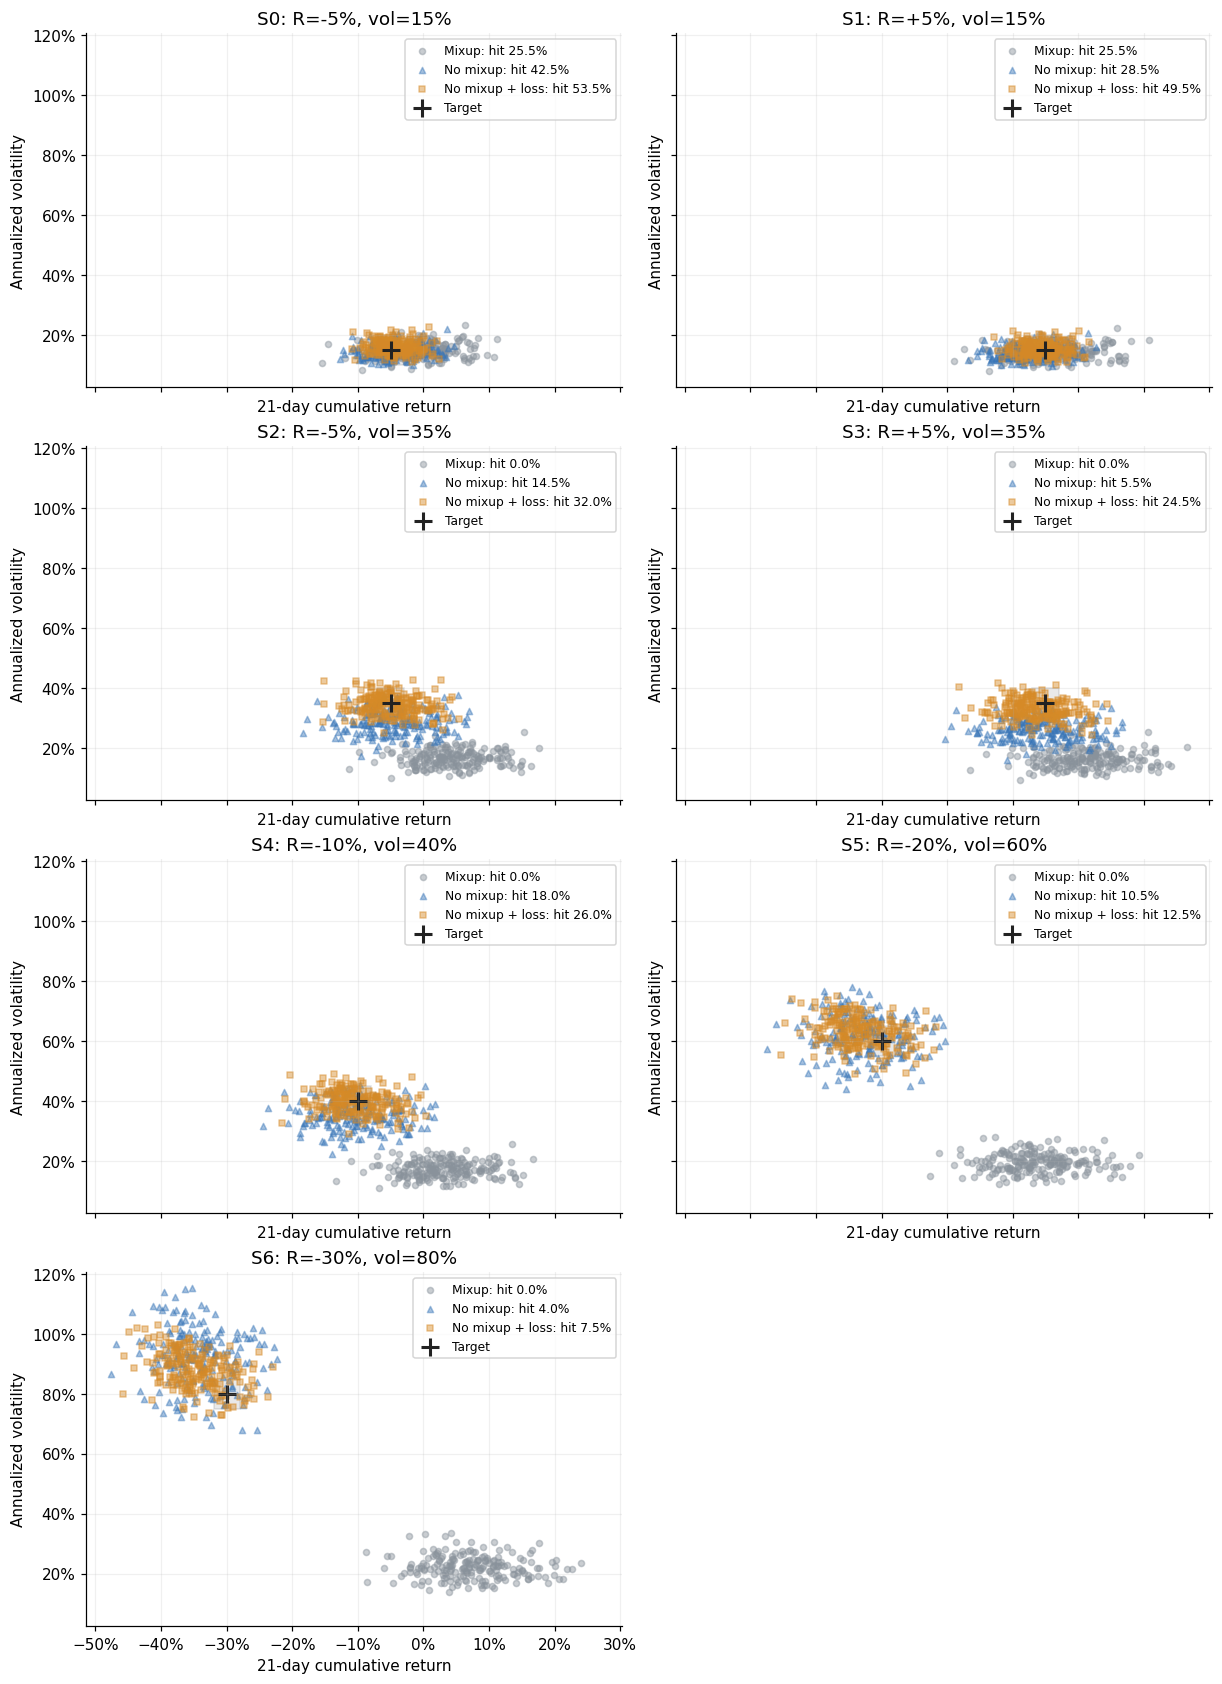

In [5]:
fig, axes = plt.subplots((len(targets)+1)//2, 2, figsize=(11, 3.8*((len(targets)+1)//2)), sharex=True, sharey=True, constrained_layout=True)
for scenario, ax in enumerate(axes.flat):
    if scenario >= len(targets):
        ax.set_visible(False)
        continue
    r, v = targets[scenario]
    ax.add_patch(Rectangle((r-TOL_R, v-TOL_V), 2*TOL_R, 2*TOL_V,
                           facecolor='#777777', edgecolor='#555555', alpha=.16))
    for label, marker in MARKERS.items():
        g = metrics[(metrics.method == label) & (metrics.scenario == scenario)]
        ax.scatter(g.actual_return, g.actual_volatility, color=COLORS[label], marker=marker,
                   s=16, alpha=.45, label=f'{label}: hit {g.hit.mean():.1%}')
    ax.scatter([r], [v], color='#222222', marker='+', s=150, linewidths=2, label='Target')
    ax.set_title(f'S{scenario}: R={r:+.0%}, vol={v:.0%}')
    ax.set_xlabel('21-day cumulative return')
    ax.set_ylabel('Annualized volatility')
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(fontsize=8)
fig.savefig(EXPORT/'joint_conditions.png', dpi=150)
plt.show()


## 6. 訓練與驗證

左圖只比較 diffusion loss，不把新增的條件懲罰混入對照；Mixup 與 No mixup 的 train_loss 即 diffusion loss。
右圖為完整採樣後的標準化條件誤差，越低越好。記錄的是當下 batch，不是 epoch 平均。
三組各自依相同驗證規則選模；驗證只取前 4 個 batch（128 個重疊窗口），不代表整個驗證期間。
標記點為各組最佳 checkpoint；不能直接比較三組的 total training loss 作為品質結論。

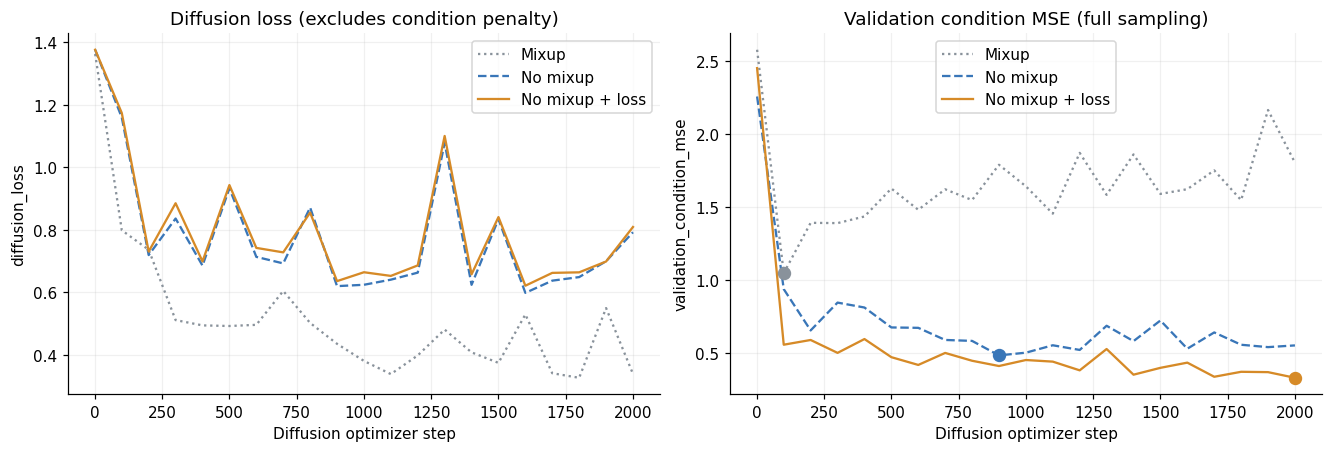

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for label, data in loaded.items():
    log = data['training']
    for ax, column in zip(axes, ['train_loss', 'validation_condition_mse']):
        values = log['diffusion_loss'] if column == 'train_loss' and 'diffusion_loss' in log else log[column]
        ax.plot(log.step, values, color=COLORS[label], linestyle=STYLES[label], label=label)
        ax.set_xlabel('Diffusion optimizer step')
        ax.set_ylabel('diffusion_loss' if column == 'train_loss' else column)
        ax.legend()
    best = data['meta']['best_step']
    score = data['meta']['best_validation_condition_mse']
    axes[1].scatter([best], [score], color=COLORS[label], s=60, zorder=5)
axes[0].set_title('Diffusion loss (excludes condition penalty)')
axes[1].set_title('Validation condition MSE (full sampling)')
fig.savefig(EXPORT/'training_curves.png', dpi=150)
plt.show()


## 7. 路徑樣貌與限制

每組只畫編號 0–9 的路徑，避免挑選看起來較好的樣本。起點指數設為 100；虛線終點為指定累積報酬。
此圖只協助觀察形狀，不能取代尾端、波動聚集、回撤等市場真實性檢查。
OHLC 符號修正比例已列於上表：修正後價格合法不等於原始生成品質合格。

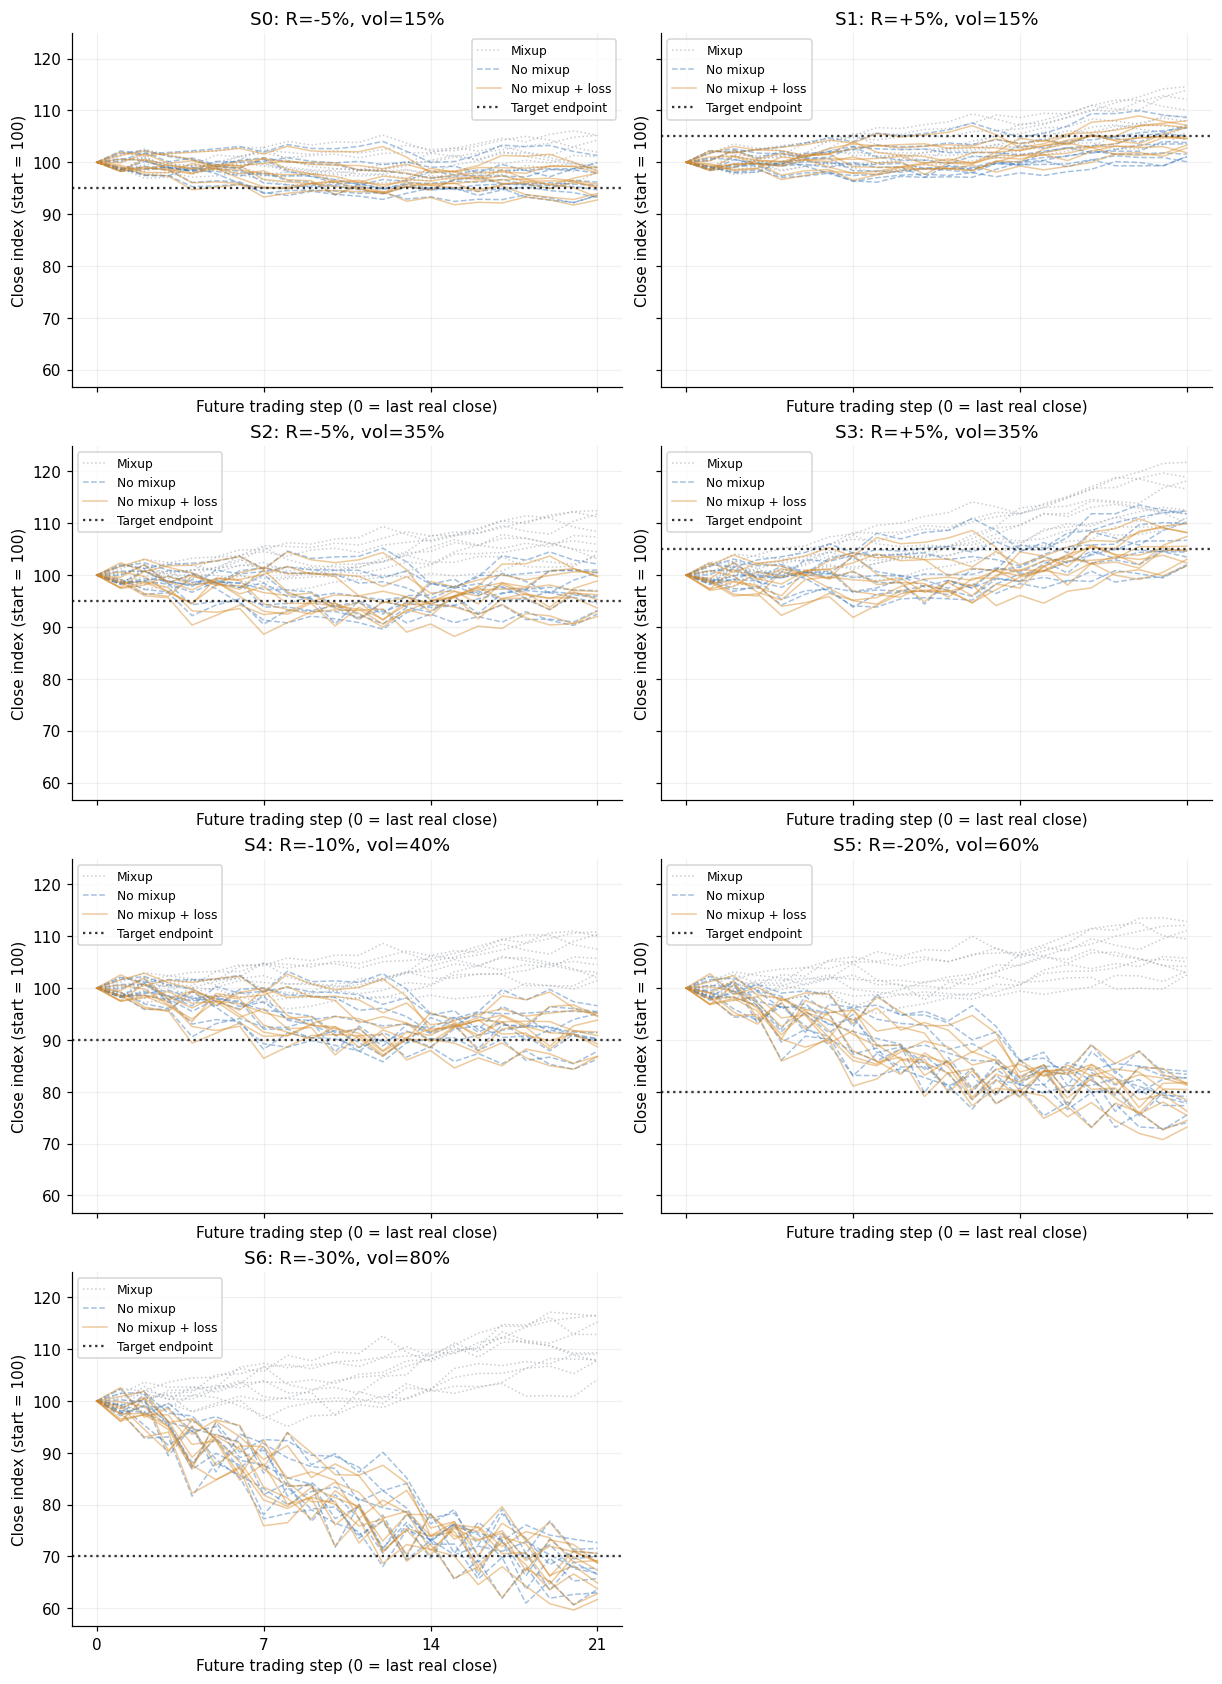

In [7]:
fig, axes = plt.subplots((len(targets)+1)//2, 2, figsize=(11, 3.8*((len(targets)+1)//2)), sharex=True, sharey=True, constrained_layout=True)
for scenario, ax in enumerate(axes.flat):
    if scenario >= len(targets):
        ax.set_visible(False)
        continue
    for label, data in loaded.items():
        paths = data['paths']
        for path_id in range(min(10, data['sampling']['n_paths'])):
            r = paths[(paths.scenario == scenario) & (paths.path == path_id)].sort_values('step').rclose.to_numpy()
            indexed = np.r_[100., 100*np.exp(np.cumsum(r))]
            ax.plot(np.arange(22), indexed, color=COLORS[label], linestyle=STYLES[label],
                    alpha=.45, linewidth=1, label=label if path_id == 0 else None)
    ax.axhline(100*(1+targets[scenario, 0]), color='#333333', linestyle=':', label='Target endpoint')
    ax.set_title(f'S{scenario}: R={targets[scenario, 0]:+.0%}, vol={targets[scenario, 1]:.0%}')
    ax.set_xlabel('Future trading step (0 = last real close)')
    ax.set_ylabel('Close index (start = 100)')
    ax.set_xticks([0, 7, 14, 21])
    ax.legend(fontsize=8)
fig.savefig(EXPORT/'example_paths.png', dpi=150)
plt.show()


## 8. 三組總覽與逐步改動效果

先列出七組等權平均與各情境命中率，再比較 **No mixup − Mixup**、**+ loss − No mixup**，
以及 **+ loss − Mixup** 的差值。MAE 差值小於零代表改善，命中率差值大於零代表改善；差值均為百分點。
生成路徑不是獨立的模型訓練重複，以下不宣稱統計顯著。

In [8]:
measure_cols = ['return_mae','volatility_mae','joint_hit_rate','rhigh_clip_rate','rlow_clip_rate']
overall = summary.groupby('method')[measure_cols].mean().reindex(RUNS)
display(overall.style.format({k: formats[k] for k in measure_cols}))
overall.to_csv(EXPORT/'overall_summary.csv')
hits = summary.pivot(index=['scenario','target_return','target_volatility'], columns='method', values='joint_hit_rate').reindex(columns=RUNS)
display(hits.style.format('{:.1%}'))
hits.to_csv(EXPORT/'joint_hit_rates.csv')
delta_rows=[]
for before_label, after_label in [('Mixup','No mixup'), ('No mixup','No mixup + loss'), ('Mixup','No mixup + loss')]:
    before=summary[summary.method==before_label].set_index('scenario')
    after=summary[summary.method==after_label].set_index('scenario')
    comparison=after[['target_return','target_volatility']].copy()
    for metric in ['return_mae','volatility_mae','joint_hit_rate']:
        comparison[metric+'_delta_pp']=100*(after[metric]-before[metric])
    comparison.insert(0,'comparison',f'{after_label} - {before_label}')
    delta_rows.append(comparison.reset_index())
    display(Markdown(f'### {after_label} − {before_label}'))
    display(comparison.drop(columns='comparison').style.format({
        'target_return':'{:+.0%}', 'target_volatility':'{:.0%}',
        **{k:'{:+.2f}' for k in comparison if k.endswith('_pp')}}))
pd.concat(delta_rows,ignore_index=True).to_csv(EXPORT/'comparison_deltas.csv',index=False)
display(Markdown('三組整體命中率依序為 **'+' → '.join(f'{v:.2%}' for v in overall.joint_hit_rate)+'**。'
    '條件控制改善仍須與路徑多樣性、High／Low 修正比例一起判讀。'))
print('圖表與彙整表：', EXPORT)


圖表與彙整表： /Users/chuanwei/Files/Projects/nycu_fintech/TimeDiff/outputs/spx/three_way_comparison


,return_mae,volatility_mae,joint_hit_rate,rhigh_clip_rate,rlow_clip_rate
method,,,,,
Mixup,14.22 pp,23.24 pp,7.29%,22.49%,13.02%
No mixup,4.16 pp,6.11 pp,17.64%,8.57%,13.24%
No mixup + loss,3.54 pp,3.74 pp,29.36%,12.77%,11.62%


,,method,Mixup,No mixup,No mixup + loss
scenario,target_return,target_volatility,,,
0,-0.050000,0.150000,25.5%,42.5%,53.5%
1,0.050000,0.150000,25.5%,28.5%,49.5%
2,-0.050000,0.350000,0.0%,14.5%,32.0%
3,0.050000,0.350000,0.0%,5.5%,24.5%
4,-0.100000,0.400000,0.0%,18.0%,26.0%
5,-0.200000,0.600000,0.0%,10.5%,12.5%
6,-0.300000,0.800000,0.0%,4.0%,7.5%


### No mixup − Mixup

,target_return,target_volatility,return_mae_delta_pp,volatility_mae_delta_pp,joint_hit_rate_delta_pp
scenario,,,,,
0,-5%,15%,-2.15,-0.35,+17.00
1,+5%,15%,-0.67,-0.26,+3.00
2,-5%,35%,-5.49,-12.05,+14.50
3,+5%,35%,-2.51,-10.19,+5.50
4,-10%,40%,-8.91,-17.44,+18.00
5,-20%,60%,-18.75,-34.87,+10.50
6,-30%,80%,-31.93,-44.72,+4.00


### No mixup + loss − No mixup

,target_return,target_volatility,return_mae_delta_pp,volatility_mae_delta_pp,joint_hit_rate_delta_pp
scenario,,,,,
0,-5%,15%,-0.64,+0.15,+11.00
1,+5%,15%,-1.33,-0.02,+21.00
2,-5%,35%,-0.72,-3.50,+17.50
3,+5%,35%,-0.82,-5.48,+19.00
4,-10%,40%,-0.66,-2.26,+8.00
5,-20%,60%,-0.21,-0.93,+2.00
6,-30%,80%,+0.05,-4.61,+3.50


### No mixup + loss − Mixup

,target_return,target_volatility,return_mae_delta_pp,volatility_mae_delta_pp,joint_hit_rate_delta_pp
scenario,,,,,
0,-5%,15%,-2.79,-0.20,+28.00
1,+5%,15%,-2.00,-0.28,+24.00
2,-5%,35%,-6.21,-15.55,+32.00
3,+5%,35%,-3.33,-15.67,+24.50
4,-10%,40%,-9.57,-19.69,+26.00
5,-20%,60%,-18.96,-35.80,+12.50
6,-30%,80%,-31.88,-49.33,+7.50


三組整體命中率依序為 **7.29% → 17.64% → 29.36%**。條件控制改善仍須與路徑多樣性、High／Low 修正比例一起判讀。

## 9. 極端條件的歷史支持

以下只使用訓練窗口。列出目標在訓練條件二維標準化空間的最近距離，以及同一命中容許區間內的窗口數。
窗口彼此重疊，不能把窗口數當成獨立事件數。區間內有歷史樣本也不保證在目前歷史背景下合理；
零窗口代表這個局部區域沒有訓練觀測，不表示數學上不可能。報酬與波動率同步調整，無法單獨識別兩個條件的作用。


In [9]:
support = pd.read_csv(RUNS['No mixup + loss']['train']/'train_conditions.csv')
scaler = new['meta']['condition_scaler']
mean, scale = np.array(scaler['mean']), np.array(scaler['scale'])
raw = support[['return', 'volatility']].to_numpy()
checks = []
for scenario, target in enumerate(targets):
    distance = np.linalg.norm((raw-target)/scale, axis=1)
    nearest = raw[distance.argmin()]
    inside = (np.abs(raw[:, 0]-target[0]) <= TOL_R) & (np.abs(raw[:, 1]-target[1]) <= TOL_V)
    checks.append(dict(scenario=scenario, target_return=target[0], target_volatility=target[1],
                       nearby_train_windows=int(inside.sum()), nearest_distance_z=distance.min(),
                       nearest_return=nearest[0], nearest_volatility=nearest[1]))
support_check = pd.DataFrame(checks)
support_check.to_csv(EXPORT/'training_support.csv', index=False)
display(support_check.style.format({k:'{:.1%}' for k in
    ['target_return','target_volatility','nearest_return','nearest_volatility']}))
display(support.agg(['min','max']).style.format('{:.1%}'))
# Compare the original four and newly added crash conditions separately.
by_group = summary.assign(group=np.where(summary.scenario < 4, 'Original four', 'Crash three'))
group_summary = by_group.groupby(['group','method'])[measure_cols].mean()
display(group_summary.style.format({k:formats[k] for k in measure_cols}))
group_summary.to_csv(EXPORT/'group_summary.csv')


,scenario,target_return,target_volatility,nearby_train_windows,nearest_distance_z,nearest_return,nearest_volatility
0,0,-5.0%,15.0%,324,0.024725,-5.1%,15.0%
1,1,5.0%,15.0%,648,0.005797,5.0%,15.0%
2,2,-5.0%,35.0%,47,0.067117,-5.1%,35.7%
3,3,5.0%,35.0%,22,0.011445,5.0%,34.9%
4,4,-10.0%,40.0%,21,0.248942,-9.5%,37.5%
5,5,-20.0%,60.0%,2,0.193543,-19.6%,58.1%
6,6,-30.0%,80.0%,5,0.016507,-30.0%,80.2%


,return,volatility
min,-33.0%,3.5%
max,25.1%,97.6%


## 10. 一致性 loss 分項與已有計時

只有 No mixup + loss 使用條件一致性懲罰；先核對兩項加權後確實等於記錄的條件 loss，
再核對 total loss = diffusion loss + 條件 loss。曲線是記錄 batch 的值，並非完整生成後的誤差。

計時只列來源中確實保存的值；缺少者標示「未記錄」，不填 0、不推估，也不作跨版本速度排名。
階段 total 與子項不可重複加總；training/sample 內部計時不含 Python 啟動與 import。
這些是既有實驗的時間，不是本 notebook 本次執行耗時。

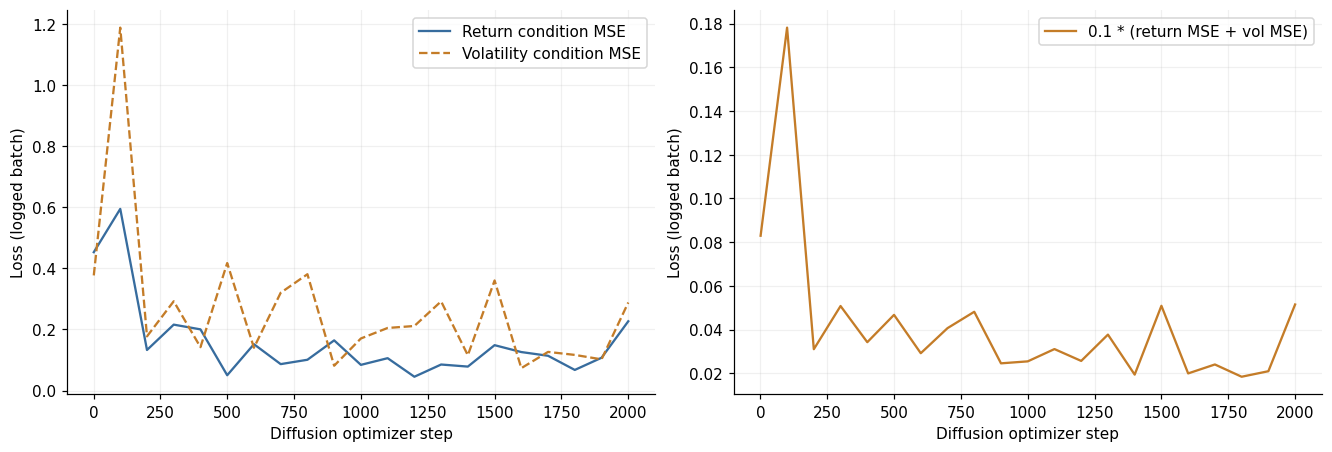

,method,stage,component,seconds
0,Mixup,Training,未記錄,未記錄
1,Mixup,Sampling,未記錄,未記錄
2,No mixup,Training,未記錄,未記錄
3,No mixup,Sampling,未記錄,未記錄
4,No mixup + loss,Training,data_model_setup_seconds,0.79
5,No mixup + loss,Training,ar_pretraining_seconds,0.49
6,No mixup + loss,Training,diffusion_update_seconds,233.65
7,No mixup + loss,Training,validation_seconds,137.04
8,No mixup + loss,Training,other_logging_checkpoint_seconds,0.92
9,No mixup + loss,Training,total_seconds,372.88


In [10]:
log = new['training']
np.testing.assert_allclose(log.weighted_condition_loss, .1*(log.return_condition_loss+log.volatility_condition_loss),rtol=1e-5,atol=1e-7)
np.testing.assert_allclose(log.train_loss, log.diffusion_loss+log.weighted_condition_loss,rtol=1e-5,atol=1e-7)
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].plot(log.step, log.return_condition_loss, label='Return condition MSE', color='#376C9E')
axes[0].plot(log.step, log.volatility_condition_loss, label='Volatility condition MSE', color='#C47C28', linestyle='--')
axes[1].plot(log.step, log.weighted_condition_loss, label='0.1 * (return MSE + vol MSE)', color='#C47C28')
for ax in axes:
    ax.set_xlabel('Diffusion optimizer step')
    ax.set_ylabel('Loss (logged batch)')
    ax.legend()
fig.savefig(EXPORT/'condition_loss_components.png', dpi=150)
plt.show()
timing_rows=[]
for label, locations in RUNS.items():
    for stage, key in [('Training','train'), ('Sampling','samples')]:
        timing_path=locations[key]/'timings.json'
        if not timing_path.exists():
            timing_rows.append(dict(method=label,stage=stage,component='未記錄',seconds=np.nan))
            continue
        timing=json.loads(timing_path.read_text())
        timing_rows.extend(dict(method=label,stage=stage,component=k,seconds=v)
                           for k,v in timing.items() if k.endswith('_seconds'))
timing_table=pd.DataFrame(timing_rows)
display(timing_table.style.format({'seconds':'{:.2f}'},na_rep='未記錄'))
timing_table.to_csv(EXPORT/'phase_timings.csv',index=False)


## 判讀與限制

- 移除 mixup 後，暴跌情境的方向與幅度控制改善；加入 λ=0.1 又提高七組情境的命中率。
- + loss 對 −30%／80% 情境仍有偏差，不能把「平均接近」解讀成逐路徑精準命中。
- 加入 loss 後 High 符號修正比例變高；條件一致性不代表所有市場結構都更真實。
- 極端目標附近的訓練窗口彼此重疊，不能當成獨立事件，也不能宣稱是生成器完全未見狀態。
- 只有一個歷史起點、seed 與一個非零 λ。沒有 CFG、沒有 RL 評估，不能據此認定最佳權重或策略穩健性。

這份 notebook 與前幾份使用相同結果檔，並新增三組並列與逐步差值；輸出僅寫入獨立的 `outputs/spx/three_way_comparison/`。
